# Avaliação Comparativa de Abordagens de RAG (GraphRAG local / global / drift)

**Objetivo:** avaliar, com as mesmas métricas de classificação usadas em `avaliacao_graphrag.ipynb`,
qual abordagem de busca do GraphRAG identifica melhor a doença hepática principal de cada prontuário.

**Ground truth:** anotação manual de 141 prontuários (`../progresso/ground_truth_anotado.csv`).

**Abordagens comparadas:** os métodos de busca nativos do `graphrag query` CLI
([documentação](https://microsoft.github.io/graphrag/query/overview/)) — todos rodando sobre o
**mesmo índice** já indexado, então a comparação isola o efeito do *método de busca*:

| Método   | Como funciona |
|----------|---------------|
| `local`  | Busca vetorial em entidades/relacionamentos + expande pelo grafo local (comunidades próximas). Bom para perguntas específicas sobre um documento/entidade. |
| `global` | Faz map-reduce sobre os *community reports* de todo o grafo. Bom para perguntas amplas sobre o dataset inteiro. |
| `drift`  | Combina busca local com uma etapa de refinamento (`drift`) guiada por sub-perguntas geradas dinamicamente. Tenta unir a precisão do local com contexto mais amplo do global. |
| `basic`  | RAG "tradicional" — busca vetorial sobre os `text_units` (chunks), sem usar o grafo. Seria o **baseline sem grafo**, mas está **desativado por padrão** aqui — ver aviso abaixo. |

O LLM configurado em `settings.yaml` é servido via **OpenRouter** (`api_base` aponta para
`openrouter.ai`), então a chave de API (`GRAPHRAG_API_KEY`) é lida do `.env` do projeto.

> ⚠️ **`basic` search não funciona neste índice.** `../experimentos/local/output/lancedb/` só tem as
> tabelas `entity-description` e `community-full_content` — falta a tabela de embeddings dos
> `text_units`, que é a única fonte de contexto do método `basic`. Sem ela o `graphrag query --method
> basic` quebra com `AttributeError: 'NoneType' object has no attribute 'search'`. Por isso `basic` foi
> **removido de `METHODS`** por padrão; para reativá-lo é preciso reindexar com embeddings de
> `text_units` habilitados (fora do escopo deste notebook).

> ⚠️ **`global` e `drift` quebram sem o hotfix `graphrag_json_patch.py`.** O passo "map" da busca
> `global` e o "primer" da busca `drift` (no `graphrag==2.7.x` instalado) forçam
> `response_format={"type": "json_object"}` na chamada ao LLM, **ignorando** o
> `model_supports_json: false` já configurado em `settings.yaml`. Contra o modelo/roteamento atual da
> OpenRouter isso quebra com `Model '...' does not support 'json_object' response format`. Por isso as
> queries aqui rodam via `uv run python run_graphrag.py query ...` (não `uv run graphrag query ...`) —
> `run_graphrag.py` importa `graphrag_json_patch.py` antes de carregar o GraphRAG, removendo esse
> `response_format` forçado (o parsing de JSON do GraphRAG já é tolerante a isso).

> ⚠️ **O GraphRAG não recupera um prontuário pelo número.** A tentativa inicial de perguntar
> "qual a doença do prontuário nº X" e deixar o índice achar o paciente certo **não funciona de forma
> confiável** — a busca vetorial/por grafo não garante localizar os chunks daquele paciente específico.
> Por isso cada query aqui **embute o texto bruto do prontuário diretamente no prompt** (todas as
> evoluções/anamneses daquele paciente, concatenadas) — custa mais tokens, mas garante que o LLM está
> de fato analisando o paciente certo. O papel de cada método de busca do GraphRAG passa a ser
> complementar esse texto com conhecimento do grafo construído sobre a base inteira (entidades,
> comunidades, relações), não "achar" o paciente.

> ⚠️ **Rode `uv sync` antes de coletar, não em paralelo dentro do notebook.** As queries
> chamam `uv run --no-sync python run_graphrag.py ...`. Sem `--no-sync`, cada `uv run`
> dispara um `uv sync` implícito — e como `collect_method` roda várias chamadas ao mesmo
> tempo (`MAX_WORKERS` threads), vários `uv sync` concorrentes disputam o mesmo `.venv`
> (inclusive o symlink `lib64 -> lib`). Em disco montado do Windows via WSL (`/mnt/c/...`)
> isso quebra com `Acesso negado (os error 5)` ou processos derrubados no meio de um
> `import` — foi a causa real do método `drift` ter falhado quase 100% das vezes em uma
> rodada anterior (139/141 prontuários com o mesmo erro, todos gravados em ~3 segundos, ou
> seja, sem sequer chegar a rodar a query de verdade). Se as dependências mudarem, rode
> `uv sync` manualmente uma vez (fora do notebook) antes de coletar.

> ⚠️ **Custo/tempo:** cada chamada ao CLI do GraphRAG carrega os parquets do índice e faz pelo menos
> 1 chamada ao LLM (agora com um prompt maior, por causa do texto do prontuário embutido). Com o
> modelo "thinking" configurado, uma única query pode levar vários minutos — em teste, uma chamada
> chegou a levar mais de 30 minutos. Rodar os 3 métodos para os ~141 prontuários é uma operação
> **longa**. Por isso o notebook:
> - **cacheia cada resposta em disco** (`../results/rag_comparison/raw/<método>/<prontuario_id>.json`) —
>   se a célula de coleta for interrompida, rodar de novo só busca o que falta;
> - expõe `N_SAMPLE` no topo para testar com poucos prontuários antes de rodar tudo;
> - permite paralelismo configurável via `MAX_WORKERS` (cuidado com rate limit da OpenRouter).


In [1]:
%pip install -q scikit-learn python-dotenv

%pip install tqdm

/mnt/c/Users/Matheus/Documents/trabalho de conclusão de curso/anamnese/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
/mnt/c/Users/Matheus/Documents/trabalho de conclusão de curso/anamnese/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import logging
import os
import re
import subprocess
import time
import unicodedata
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from sklearn.metrics import (
    precision_recall_fscore_support,
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
)

import warnings
warnings.filterwarnings("ignore")

# Paleta clínica (mesma linguagem visual do avaliacao_graphrag.ipynb) + 1 cor por método
COR_OK      = '#3BB273'   # verde
COR_BASE    = '#E84855'   # vermelho
COR_NEUTRO  = '#A8DADC'   # azul claro

CORES_METODO = {
    'local':  '#2E86AB',   # azul
    'global': '#E8871E',   # laranja
    'drift':  '#8E44AD',   # roxo
    'basic':  '#6C757D',   # cinza (baseline sem grafo)
}

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'font.family': 'DejaVu Sans',
})

print('OK')


/mnt/c/Users/Matheus/Documents/trabalho de conclusão de curso/anamnese/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK


## 1. Configuração

In [20]:
# ── Caminhos ────────────────────────────────────────────────────────────────
PROJECT_ROOT     = Path("..").resolve()
GROUND_TRUTH_CSV = PROJECT_ROOT / "progresso" / "ground_truth_anotado.csv"

GRAPHRAG_ROOT = PROJECT_ROOT / "experimentos" / "local"          # raiz do índice já construído
GRAPHRAG_DATA = GRAPHRAG_ROOT / "output"                          # parquets do índice

# Fontes do texto bruto de cada prontuário (evoluções/anamnese), usadas para montar
# o contexto injetado em cada query — o GraphRAG não recupera um paciente pelo nº
# de prontuário de forma confiável, então o texto precisa ir explícito no prompt.
# A 1ª fonte é mais completa para os prontuários do ground truth; a 2ª cobre o resto.
PRONTUARIO_SOURCES = [
    PROJECT_ROOT / "data" / "12-07-2025-FALTA-ANONIMIZAR-Anamnese_evolucao-HEPATOLOGIA.csv",
    PROJECT_ROOT / "data" / "coluna-evolucoes_anonimizadas.csv",
]
MAX_CHARS_PRONTUARIO = 20_000  # ~5-6k tokens por prontuário; None = sem truncar (mais fiel, mais caro)

RESULTS_DIR = PROJECT_ROOT / "results" / "rag_comparison"
RAW_DIR     = RESULTS_DIR / "raw"           # respostas brutas, 1 json por (método, prontuário)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True, exist_ok=True)

# ── Métodos a comparar (na ordem em que aparecem nos gráficos) ───────────────
# 'basic' fica de fora por padrão: o índice em experimentos/local não tem a tabela
# de embeddings de text_units que esse método exige (ver aviso na célula anterior).
METHODS = ["basic", "local", "global"]

# ── Execução ───────────────────────────────────────────────────────────────
N_SAMPLE       = None   # None = todos os prontuários do ground truth; int = amostra p/ teste rápido
MAX_WORKERS    = 4      # chamadas paralelas ao `graphrag query` (cada uma é 1 processo CLI)
QUERY_TIMEOUT  = 1200   # segundos por query (modelo "thinking" pode ser lento; visto >30min em teste)
COMMUNITY_LEVEL = 2     # mesmo nível usado em scripts/query.sh (COMMUNITY_LEVEL_MEDIUM)
RESPONSE_TYPE   = "Single sentence"
FORCE_RERUN     = False  # True para ignorar cache e refazer todas as queries

CLASSES = [
    'cirrose_hepatica', 'esquistossomose', 'hepatite_c', 'hepatite_b',
    'esteatose_hepatica', 'hipertensao_portal', 'hemorragia_digestiva_alta', 'pbe',
]
LABELS_PT = {
    'cirrose_hepatica':          'Cirrose hepática',
    'esquistossomose':           'Esquistossomose',
    'hepatite_c':                'Hepatite C',
    'hepatite_b':                'Hepatite B',
    'esteatose_hepatica':        'Esteatose hepática',
    'hipertensao_portal':        'Hipertensão portal',
    'hemorragia_digestiva_alta': 'Hemorragia digestiva alta',
    'pbe':                       'PBE',
    'nenhuma':                   'Nenhuma',
}
print(f"GRAPHRAG_ROOT: {GRAPHRAG_ROOT}  (existe: {GRAPHRAG_ROOT.exists()})")
print(f"Métodos: {METHODS}")


GRAPHRAG_ROOT: /mnt/c/Users/Matheus/Documents/trabalho de conclusão de curso/anamnese/experimentos/local  (existe: True)
Métodos: ['basic', 'local', 'global']


In [5]:
# ── Chave de API (OpenRouter, via .env do projeto) ────────────────────────────
from dotenv import load_dotenv

load_dotenv(PROJECT_ROOT / ".env")

API_KEY = os.environ.get("GRAPHRAG_API_KEY", "")
if not API_KEY:
    raise RuntimeError(
        f"GRAPHRAG_API_KEY não encontrada. Defina-a em {PROJECT_ROOT / '.env'} "
        "(é a chave usada em settings.yaml para autenticar na OpenRouter)."
    )
os.environ["GRAPHRAG_API_KEY"] = API_KEY  # garante que o subprocess do graphrag CLI a herde
print(f"GRAPHRAG_API_KEY carregada ({len(API_KEY)} caracteres).")


GRAPHRAG_API_KEY carregada (73 caracteres).


## 2. Texto bruto de cada prontuário (para injetar no prompt)

O GraphRAG não indexa/recupera um prontuário específico só pelo número — por isso montamos aqui,
a partir dos CSVs-fonte (não o índice), o texto de todas as evoluções/anamneses de cada paciente do
ground truth, ordenadas por data. Esse texto é o que vai dentro de cada query (célula da seção 4).


In [6]:
def _read_source_csv(path: Path) -> pd.DataFrame:
    """Alguns CSVs-fonte têm uma linha de título antes do cabeçalho real; detecta e pula."""
    df = pd.read_csv(path, dtype=str)
    if "prontuario" not in df.columns:
        df = pd.read_csv(path, dtype=str, header=1)
    return df


def load_prontuario_texts(prontuario_ids: list[str]) -> dict[str, str]:
    """
    Monta prontuario_id -> texto (todas as evoluções concatenadas, mais recentes
    primeiro se precisar truncar). Usa a união das fontes em PRONTUARIO_SOURCES,
    removendo duplicatas exatas de (prontuario, descricao) entre elas.
    """
    wanted = set(prontuario_ids)
    frames = []
    for path in PRONTUARIO_SOURCES:
        if not path.exists():
            print(f"  aviso: fonte não encontrada, ignorando: {path}")
            continue
        df = _read_source_csv(path)
        df["prontuario"] = df["prontuario"].astype(str).str.strip()
        df = df[df["prontuario"].isin(wanted)]
        frames.append(df[["prontuario", "descricao", "data_atendimento"]])

    if not frames:
        raise RuntimeError("Nenhuma fonte de prontuários pôde ser lida — verifique PRONTUARIO_SOURCES.")

    todos = pd.concat(frames, ignore_index=True)
    todos["descricao"] = todos["descricao"].fillna("")
    todos = todos.drop_duplicates(subset=["prontuario", "descricao"])
    todos = todos.sort_values(["prontuario", "data_atendimento"])

    textos: dict[str, str] = {}
    for pid, grupo in todos.groupby("prontuario"):
        partes = [
            f"--- Atendimento em {row.data_atendimento} ---\n{row.descricao}".strip()
            for row in grupo.itertuples()
            if row.descricao.strip()
        ]
        if not partes:
            continue

        texto = "\n\n".join(partes)
        if MAX_CHARS_PRONTUARIO and len(texto) > MAX_CHARS_PRONTUARIO:
            # trunca mantendo as evoluções mais recentes (mais relevantes p/ dx atual)
            mantidas, total = [], 0
            for parte in reversed(partes):
                if total + len(parte) > MAX_CHARS_PRONTUARIO:
                    break
                mantidas.append(parte)
                total += len(parte)
            texto = (
                "[...evoluções mais antigas omitidas por limite de tamanho...]\n\n"
                + "\n\n".join(reversed(mantidas))
            )
        textos[pid] = texto

    faltando = wanted - set(textos.keys())
    if faltando:
        print(
            f"  aviso: {len(faltando)} prontuário(s) do ground truth sem texto-fonte "
            f"encontrado (serão pulados na coleta): {sorted(faltando)}"
        )

    return textos


## 3. Normalização de doenças (MAPA) e parsing da resposta em texto livre

O `graphrag query` devolve texto livre (não uma classe). Para transformar isso em uma das 8 classes do
ground truth, procuramos no texto da resposta por qualquer uma das variações de nome de doença abaixo
(mesmo dicionário usado em `avaliacao_graphrag.ipynb`, comparando sem acentos/caixa para tolerar
variações do LLM) e escolhemos a classe mais mencionada.


In [7]:
MAPA = {
    'CIRROSE': 'cirrose_hepatica', 'CIRROSE HEPATICA': 'cirrose_hepatica',
    'CIRROSE HEPÁTICA': 'cirrose_hepatica', 'CIRROSE HEPÁTICA DESCOMPENSADA': 'cirrose_hepatica',
    'CIRROSE HEPÁTICA ALCOÓLICA': 'cirrose_hepatica', 'CIRROSE HEPÁTICA VIRAL C': 'cirrose_hepatica',
    'CIRROSE MICRONODULAR': 'cirrose_hepatica', 'CIRROSE DESCOMPENSADA': 'cirrose_hepatica',
    'CIRROSE HEPÁTICA CRÔNICA': 'cirrose_hepatica',
    'HIPERTENSAO PORTAL': 'hipertensao_portal', 'HIPERTENSÃO PORTAL': 'hipertensao_portal',
    'HIPERTENSÃO PORTA': 'hipertensao_portal', 'SINDROME DE HIPERTENSAO PORTAL': 'hipertensao_portal',
    'SÍNDROME DE HIPERTENSÃO PORTAL': 'hipertensao_portal', 'SÍNDROME DA HIPERTENSÃO PORTAL': 'hipertensao_portal',
    'HIPERTENSÃO PORTAL NÃO CIRRÓTICA': 'hipertensao_portal', 'HIPERTENSÃO PORTAL NÃO-CIRRÓTICA': 'hipertensao_portal',
    'EHE/HP': 'hipertensao_portal',
    'ESQUISTOSSOMOSE': 'esquistossomose', 'EQUISTOSSOMOSE': 'esquistossomose',
    'ESQUISTOSSOMOSE HEPATOESPLENICA': 'esquistossomose', 'ESQUISTOSSOMOSE HEPATOESPLÊNICA': 'esquistossomose',
    'ESQUISTOSSOMOSE HEPATOESPLÊNICA (EHE)': 'esquistossomose', 'ESQUISTOSSOMOSE MANSONI': 'esquistossomose',
    'ESQUISTOSSOMOSE MANSÔNICA': 'esquistossomose', 'EHE': 'esquistossomose',
    'HEPATITE C': 'hepatite_c', 'HEPATITE C (HCV)': 'hepatite_c',
    'HEPATITE C CRÔNICA': 'hepatite_c', 'HEPATITE CRÔNICA VIRAL': 'hepatite_c',
    'HEPATITE B': 'hepatite_b', 'HEPATITE B (HBV)': 'hepatite_b',
    'HEPATITE B CRONICA': 'hepatite_b', 'HEPATITE B INATIVA': 'hepatite_b',
    'HEPATITE B RESOLVIDA': 'hepatite_b', 'HEPATITE CRÔNICA B': 'hepatite_b',
    'HEPATITE CRÔNICA VIRAL B': 'hepatite_b', 'VÍRUS B (HEPATITE B)': 'hepatite_b',
    'ESTEATOSE': 'esteatose_hepatica', 'ESTEATOSE HEPATICA': 'esteatose_hepatica',
    'ESTEATOSE HEPÁTICA': 'esteatose_hepatica', 'ESTEATOSE HEPATICA DIFUSA': 'esteatose_hepatica',
    'DHGNA': 'esteatose_hepatica', 'NAFLD': 'esteatose_hepatica',
    'MASLD': 'esteatose_hepatica', 'MASH': 'esteatose_hepatica', 'NASH': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA GORDUROSA NÃO ALCOÓLICA': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA GORDUROSA NÃO ALCOÓLICA (DHGNA)': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA ESTEATÓTICA METABÓLICA': 'esteatose_hepatica',
    'DOENÇA HEPÁTICA ESTEATÓTICA METABÓLICA (MASH)': 'esteatose_hepatica',
    'ESTEATO-HEPATITE NÃO ALCOÓLICA': 'esteatose_hepatica',
    'ESTEATO-HEPATITE NÃO ALCOÓLICA (NASH)': 'esteatose_hepatica',
    'ESTEATOHEPATITE': 'esteatose_hepatica', 'ESTEATOHEPATITE NÃO ALCOÓLICA': 'esteatose_hepatica',
    'HDA': 'hemorragia_digestiva_alta', 'HEMORRAGIA DIGESTIVA ALTA': 'hemorragia_digestiva_alta',
    'HDA (HEMORRAGIA DIGESTIVA ALTA)': 'hemorragia_digestiva_alta', 'HDA VARICOSA': 'hemorragia_digestiva_alta',
    'HEMORRAGIA DIGESTIVA ALTA VARICOSA': 'hemorragia_digestiva_alta', 'HEMORRAGIA VARICOSA': 'hemorragia_digestiva_alta',
    'PBE': 'pbe', 'PERITONITE BACTERIANA ESPONTÂNEA': 'pbe',
    'PBE (PERITONITE BACTERIANA ESPONTÂNEA)': 'pbe', 'PERITONITE BACTERIANA ESPONTANEA': 'pbe',
}

_NEGACOES = (
    'NENHUMA', 'NAO IDENTIFI', 'NÃO IDENTIFI', 'NAO ENCONTR', 'NÃO ENCONTR',
    'NAO HA EVIDENCIA', 'NÃO HÁ EVIDÊNCIA', 'SEM EVIDENCIA', 'SEM EVIDÊNCIA',
    'NAO FOI POSSIVEL', 'NÃO FOI POSSÍVEL', 'INFORMACAO INSUFICIENTE', 'INFORMAÇÃO INSUFICIENTE',
    'NAO CONSTA', 'NÃO CONSTA', "DATA NOT FOUND", "I AM SORRY", "I'M SORRY",
)


def _strip_accents(s: str) -> str:
    nfd = unicodedata.normalize('NFD', s)
    return ''.join(c for c in nfd if unicodedata.category(c) != 'Mn')


def _norm(s: str) -> str:
    return _strip_accents(s).upper().strip()


# Chaves do MAPA pré-normalizadas (sem acento, maiúsculas), ordenadas da mais
# longa para a mais curta para que frases específicas sejam testadas antes de
# siglas curtas (ex.: 'HEPATITE B' antes de matches genéricos).
_MAPA_NORM = sorted(
    ((_norm(k), v) for k, v in MAPA.items()),
    key=lambda kv: len(kv[0]),
    reverse=True,
)


def parse_disease_from_response(text: str) -> str:
    """Extrai a classe de doença (uma das 8 + 'nenhuma') de uma resposta em texto livre."""
    if not text or text.startswith(('ERROR:', 'SKIPPED:')):
        return 'nenhuma'

    norm_text = _norm(text)

    contagem: dict[str, int] = {}
    primeira_posicao: dict[str, int] = {}
    for chave, classe in _MAPA_NORM:
        pos = norm_text.find(chave)
        if pos == -1:
            continue
        contagem[classe] = contagem.get(classe, 0) + norm_text.count(chave)
        primeira_posicao.setdefault(classe, pos)

    if not contagem:
        return 'nenhuma'

    # desempate: mais mencionada; empate → a que aparece primeiro no texto
    melhor = sorted(contagem.items(), key=lambda kv: (-kv[1], primeira_posicao[kv[0]]))[0][0]

    # se a resposta nega explicitamente e só bateu por acaso em outra parte do texto
    # (ex.: "não há evidência de esteatose hepática"), preferimos 'nenhuma'.
    if any(neg in norm_text for neg in _NEGACOES) and len(contagem) == 1:
        return 'nenhuma'

    return melhor


# Sanity check rápido
assert parse_disease_from_response('O paciente apresenta Esteatose Hepática difusa.') == 'esteatose_hepatica'
assert parse_disease_from_response('Não há evidência de cirrose hepática no prontuário.') == 'nenhuma'
assert parse_disease_from_response('') == 'nenhuma'
print('Parser OK.')


Parser OK.


## 4. Execução das queries via `graphrag query` CLI

In [21]:
def build_query(prontuario_id: str) -> str | None:
 
    texto = TEXTOS_PRONTUARIO.get(prontuario_id)
    if not texto:
        return None

    return (
        "Abaixo estão as evoluções/anamneses de um único paciente, extraídas do prontuário "
        f"eletrônico (nº {prontuario_id}). Com base EXCLUSIVAMENTE nesse conteúdo (usando seu "
        "conhecimento médico geral apenas para interpretá-lo), qual é a doença hepática principal "
        "desse paciente? Escolha apenas uma entre: Cirrose hepática, Esquistossomose, Hepatite B, "
        "Hepatite C, Esteatose hepática, Hipertensão portal, Hemorragia digestiva alta, "
        "Peritonite bacteriana espontânea (PBE). Se nenhuma dessas condições estiver claramente "
        "documentada, responda 'Nenhuma'. Responda em uma frase curta, citando apenas o nome da doença.\n\n"
        f"--- PRONTUÁRIO {prontuario_id} ---\n{texto}\n--- FIM DO PRONTUÁRIO {prontuario_id} ---"
    )


def run_graphrag_query(query: str, method: str, timeout: int = QUERY_TIMEOUT) -> tuple[str, bool]:
    """
    Executa `graphrag query` via subprocess e devolve (texto_resposta, sucesso).

    Roda via `run_graphrag.py` (não `graphrag` direto) para aplicar antes o hotfix
    `graphrag_json_patch.py`: sem ele, os métodos `global` e `drift` quebram contra
    modelos/roteamentos da OpenRouter que não suportam response_format=json_object
    (ex.: erro "does not support 'json_object' response format" via provider Novita).

    Usa `--no-sync`: sem essa flag, cada `uv run` faz um `uv sync` implícito antes de
    rodar. Como `collect_method` chama isso a partir de vários threads em paralelo
    (`MAX_WORKERS`), múltiplos `uv sync` concorrentes competem pelo mesmo `.venv`
    (inclusive o symlink `lib64 -> lib`) — em disco montado do Windows via WSL
    (`/mnt/c/...`) isso causa "Acesso negado (os error 5)" ou processos sendo
    derrubados no meio de um `import`. Sintoma observado: um método inteiro falhando
    quase instantaneamente para (quase) todos os prontuários, todos com o mesmo erro.
    `--no-sync` faz o `uv run` só executar, sem tocar no `.venv`/lockfile — rode
    `uv sync` manualmente uma vez antes de coletar se as dependências mudarem.
    """
    cmd = [
        "uv", "run", "--no-sync", "python", "run_graphrag.py", "query",
        "--root",            str(GRAPHRAG_ROOT),
        "--data",             str(GRAPHRAG_DATA),
        "--method",           method,
        "--community-level",  str(COMMUNITY_LEVEL),
        "--response-type",    RESPONSE_TYPE,
        "--query",            query,
    ]
    try:
        proc = subprocess.run(
            cmd,
            cwd=str(PROJECT_ROOT),
            capture_output=True,
            text=True,
            encoding="utf-8",
            timeout=timeout,
            env=os.environ,
        )
    except subprocess.TimeoutExpired:
        return f"ERROR: query timed out after {timeout}s", False
    except FileNotFoundError:
        return "ERROR: 'uv'/'graphrag' não encontrado no PATH", False
    except Exception as exc:  # noqa: BLE001
        return f"ERROR: unexpected exception — {exc}", False

    if proc.returncode == 0:
        return proc.stdout.strip(), True

    return f"ERROR: exit {proc.returncode} — {proc.stderr.strip()[-800:]}", False


In [22]:
def _raw_path(method: str, prontuario_id: str) -> Path:
    d = RAW_DIR / method
    d.mkdir(parents=True, exist_ok=True)
    return d / f"{prontuario_id}.json"


def get_or_run(prontuario_id: str, method: str, force: bool = False) -> dict:
    """Consulta o cache em disco; se ausente (ou --force), roda a query e persiste o resultado."""
    path = _raw_path(method, prontuario_id)

    if not force and path.exists():
        try:
            cached = json.loads(path.read_text(encoding="utf-8"))
            if cached.get("success") or cached.get("skipped"):
                return cached
        except (json.JSONDecodeError, OSError):
            pass

    query = build_query(prontuario_id)

    if query is None:
        record = {
            "prontuario_id": prontuario_id,
            "method": method,
            "query": None,
            "response": "SKIPPED: sem texto-fonte para este prontuário",
            "success": False,
            "skipped": True,
            "elapsed_s": 0.0,
            "timestamp": datetime.now().isoformat(timespec="seconds"),
        }
        path.write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
        return record

    t0 = time.monotonic()
    response, success = run_graphrag_query(query, method)
    elapsed = time.monotonic() - t0

    record = {
        "prontuario_id": prontuario_id,
        "method": method,
        "query": query,
        "response": response,
        "success": success,
        "skipped": False,
        "elapsed_s": round(elapsed, 1),
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }
    path.write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
    return record


def collect_method(prontuario_ids: list[str], method: str) -> pd.DataFrame:
    """Coleta (ou reaproveita do cache) as respostas de um método para todos os prontuários."""
    registros = []
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = {
            pool.submit(get_or_run, pid, method, FORCE_RERUN): pid
            for pid in prontuario_ids
        }
        barra = tqdm(as_completed(futures), total=len(futures), desc=f"método={method}")
        for fut in barra:
            registros.append(fut.result())

    df = pd.DataFrame(registros)
    df["doenca_prevista"] = df["response"].apply(parse_disease_from_response)
    df.to_csv(RESULTS_DIR / f"predictions_{method}.csv", index=False, encoding="utf-8-sig")
    return df


## 5. Carga do ground truth, texto dos prontuários, e execução da coleta

Rode a célula abaixo para disparar as queries. Se for interrompida (kernel, rede, rate limit),
rode de novo: o cache em `../results/rag_comparison/raw/` evita repetir o que já deu certo.


In [11]:
gt = pd.read_csv(GROUND_TRUTH_CSV, dtype=str, encoding="utf-8-sig").fillna("")
gt["prontuario_id"] = gt["prontuario_id"].str.strip()

prontuario_ids = gt["prontuario_id"].tolist()
if N_SAMPLE:
    prontuario_ids = prontuario_ids[:N_SAMPLE]

print("Carregando texto-fonte dos prontuários (necessário pois o GraphRAG não recupera por nº)...")
TEXTOS_PRONTUARIO = load_prontuario_texts(prontuario_ids)

tamanhos = [len(t) for t in TEXTOS_PRONTUARIO.values()]
print(f"\nGround truth total       : {len(gt)}")
print(f"Prontuários nesta rodada : {len(prontuario_ids)}  (N_SAMPLE={N_SAMPLE})")
print(f"Com texto-fonte          : {len(TEXTOS_PRONTUARIO)}/{len(prontuario_ids)}")
if tamanhos:
    print(f"Tamanho do texto (chars) : média={np.mean(tamanhos):.0f}  mediana={np.median(tamanhos):.0f}  máx={max(tamanhos)}")
print(f"Métodos                  : {METHODS}")
print(f"Total de queries (máx)   : {len(prontuario_ids) * len(METHODS)}")


Carregando texto-fonte dos prontuários (necessário pois o GraphRAG não recupera por nº)...
  aviso: 2 prontuário(s) do ground truth sem texto-fonte encontrado (serão pulados na coleta): ['10750172', '10762722']

Ground truth total       : 141
Prontuários nesta rodada : 141  (N_SAMPLE=None)
Com texto-fonte          : 139/141
Tamanho do texto (chars) : média=10890  mediana=11121  máx=19971
Métodos                  : ['basic', 'local']
Total de queries (máx)   : 282


In [ ]:
previsoes = {}  # method -> DataFrame
for metodo in METHODS:
    print(f"\n{'─'*60}\nColetando respostas — método={metodo}\n{'─'*60}")
    previsoes[metodo] = collect_method(prontuario_ids, metodo)
    n_ok = previsoes[metodo]["success"].sum()
    n_skip = previsoes[metodo].get("skipped", pd.Series(dtype=bool)).sum()
    print(f"  OK: {n_ok}/{len(previsoes[metodo])}  (pulados por falta de texto-fonte: {n_skip})")



────────────────────────────────────────────────────────────
Coletando respostas — método=basic
────────────────────────────────────────────────────────────


método=basic: 100%|██████████| 141/141 [00:00<00:00, 322.47it/s]


  OK: 139/141  (pulados por falta de texto-fonte: 2)

────────────────────────────────────────────────────────────
Coletando respostas — método=local
────────────────────────────────────────────────────────────


método=local: 100%|██████████| 141/141 [00:00<00:00, 295.32it/s]


  OK: 139/141  (pulados por falta de texto-fonte: 2)

────────────────────────────────────────────────────────────
Coletando respostas — método=global
────────────────────────────────────────────────────────────


método=global:  19%|█▉        | 27/141 [3:29:56<14:46:24, 466.53s/it]


## 6. Distribuição do ground truth

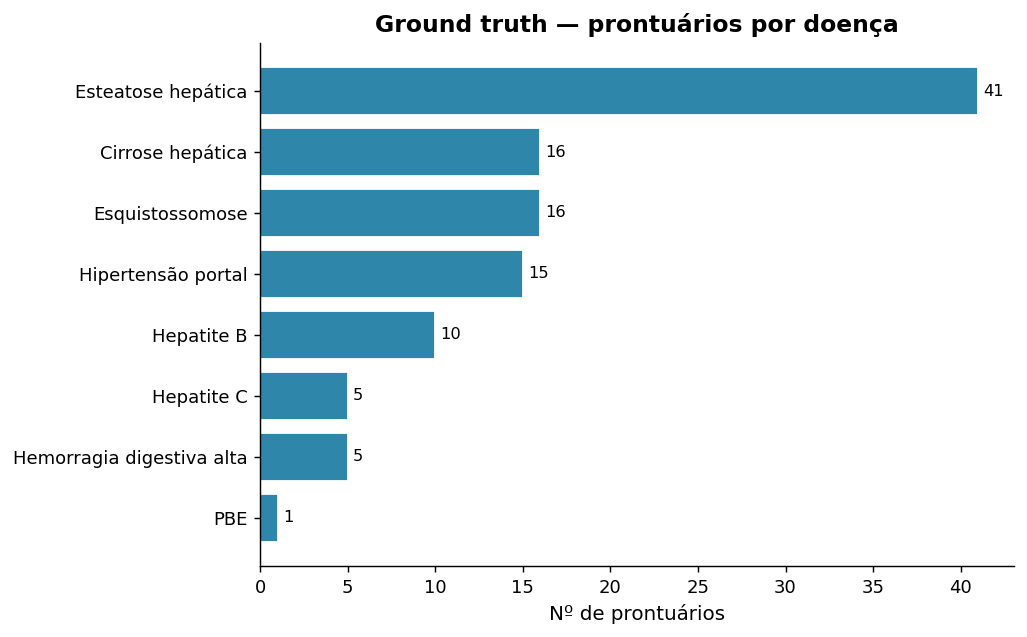

Casos avaliáveis (doença conhecida): 109
Falsos positivos puros (ground truth = nenhuma): 32


In [13]:
gt_eval = gt[gt["doenca_principal"] != "nenhuma"].copy()
gt_fp   = gt[gt["doenca_principal"] == "nenhuma"].copy()

fig, ax = plt.subplots(figsize=(8, 5))
dist = gt_eval["doenca_principal"].map(LABELS_PT).value_counts()
bars = ax.barh(dist.index[::-1], dist.values[::-1], color=CORES_METODO['local'], edgecolor='white')
for bar, v in zip(bars, dist.values[::-1]):
    ax.text(v + 0.3, bar.get_y() + bar.get_height()/2, str(v), va='center', fontsize=9)
ax.set_title('Ground truth — prontuários por doença', fontsize=13, fontweight='bold')
ax.set_xlabel('Nº de prontuários')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_ground_truth_distribuicao.png', bbox_inches='tight')
plt.show()

print(f"Casos avaliáveis (doença conhecida): {len(gt_eval)}")
print(f"Falsos positivos puros (ground truth = nenhuma): {len(gt_fp)}")


## 7. Métricas por abordagem

In [14]:
def bootstrap_f1(y_true, y_pred, n=5000):
    scores = []
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    for _ in range(n):
        idx = np.random.choice(len(y_true), len(y_true), replace=True)
        try:
            _, _, f1, _ = precision_recall_fscore_support(
                y_true[idx], y_pred[idx], average='macro', zero_division=0
            )
            scores.append(f1)
        except ValueError:
            pass
    return np.percentile(scores, [2.5, 97.5]) if scores else (np.nan, np.nan)


def avalia_metodo(method: str, df_pred: pd.DataFrame) -> dict:
    pred_by_id = df_pred.set_index("prontuario_id")["doenca_prevista"]

    df_e = gt_eval.copy()
    df_e["prevista"] = df_e["prontuario_id"].map(pred_by_id).fillna("nenhuma")

    df_f = gt_fp.copy()
    df_f["prevista"] = df_f["prontuario_id"].map(pred_by_id).fillna("nenhuma")

    y_true = df_e["doenca_principal"].tolist()
    y_pred = df_e["prevista"].tolist()
    classes_presentes = sorted(set(y_true) | set(y_pred))

    acc   = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    p_wtd, r_wtd, f1_wtd, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    ic_f1 = bootstrap_f1(y_true, y_pred)

    p_cls, r_cls, f1_cls, sup_cls = precision_recall_fscore_support(
        y_true, y_pred, labels=classes_presentes, average=None, zero_division=0
    )
    df_metricas = pd.DataFrame({
        'classe':    classes_presentes,
        'Doença':    [LABELS_PT.get(c, c) for c in classes_presentes],
        'Precision': p_cls.round(3),
        'Recall':    r_cls.round(3),
        'F1':        f1_cls.round(3),
        'Suporte':   sup_cls.astype(int),
    })

    taxa_skip = df_pred["skipped"].mean() if len(df_pred) else np.nan
    nao_skip  = df_pred[~df_pred["skipped"]] if len(df_pred) else df_pred
    taxa_erro = 1 - nao_skip["success"].mean() if len(nao_skip) else np.nan
    taxa_fp   = (df_f["prevista"] != "nenhuma").mean() if len(df_f) else np.nan

    return {
        "method": method,
        "accuracy": acc,
        "kappa": kappa,
        "f1_macro": f1_mac,
        "f1_macro_ic_low": ic_f1[0],
        "f1_macro_ic_high": ic_f1[1],
        "f1_weighted": f1_wtd,
        "precision_macro": p_mac,
        "recall_macro": r_mac,
        "taxa_erro_cli": taxa_erro,
        "taxa_sem_texto_fonte": taxa_skip,
        "taxa_falso_positivo": taxa_fp,
        "n_avaliados": len(df_e),
        "y_true": y_true,
        "y_pred": y_pred,
        "classes_presentes": classes_presentes,
        "df_metricas": df_metricas,
        "df_eval": df_e,
    }


resultados = {m: avalia_metodo(m, previsoes[m]) for m in METHODS}

df_resumo = pd.DataFrame([
    {
        "Método": m,
        "Accuracy": r["accuracy"],
        "F1 macro": r["f1_macro"],
        "IC95% F1 macro": f"[{r['f1_macro_ic_low']:.3f}, {r['f1_macro_ic_high']:.3f}]",
        "F1 weighted": r["f1_weighted"],
        "Cohen Kappa": r["kappa"],
        "Precision macro": r["precision_macro"],
        "Recall macro": r["recall_macro"],
        "Taxa erro CLI": r["taxa_erro_cli"],
        "Taxa sem texto-fonte": r["taxa_sem_texto_fonte"],
        "Taxa falso positivo": r["taxa_falso_positivo"],
    }
    for m, r in resultados.items()
]).sort_values("F1 macro", ascending=False).reset_index(drop=True)

df_resumo.to_csv(RESULTS_DIR / "resumo_comparativo_metodos.csv", index=False, encoding="utf-8-sig")
df_resumo.round(4)


,Método,Accuracy,F1 macro,IC95% F1 macro,F1 weighted,Cohen Kappa,Precision macro,Recall macro,Taxa erro CLI,Taxa sem texto-fonte,Taxa falso positivo
0,local,0.5138,0.3326,"[0.269, 0.429]",0.5443,0.4074,0.3560,0.3203,0.0,0.0142,0.4375
1,basic,0.4954,0.3266,"[0.247, 0.427]",0.5373,0.3863,0.3873,0.3008,0.0,0.0142,0.5625


## 8. Gráfico comparativo — F1 macro e Accuracy por abordagem

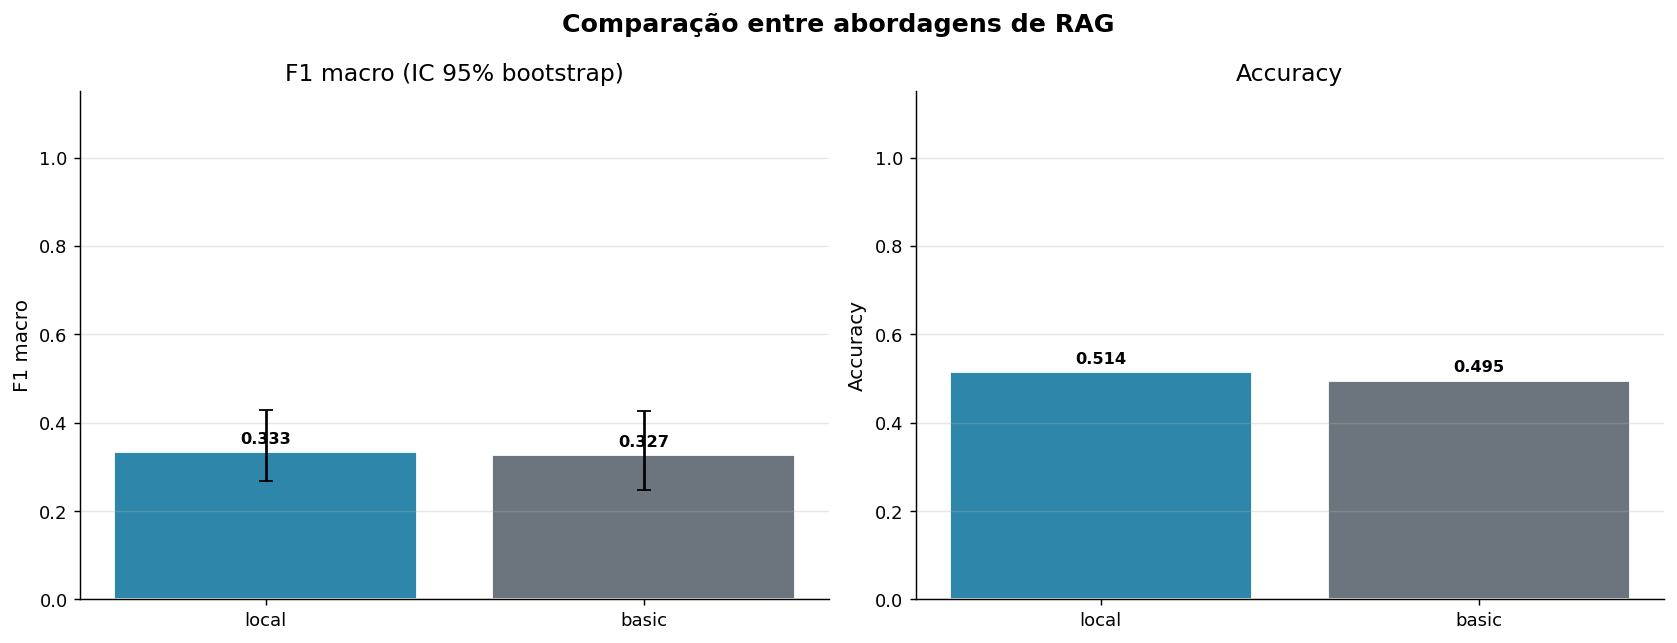

In [15]:
ordem = df_resumo["Método"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Comparação entre abordagens de RAG', fontsize=14, fontweight='bold')

ax = axes[0]
f1s   = [resultados[m]["f1_macro"] for m in ordem]
erros = [
    [resultados[m]["f1_macro"] - resultados[m]["f1_macro_ic_low"] for m in ordem],
    [resultados[m]["f1_macro_ic_high"] - resultados[m]["f1_macro"] for m in ordem],
]
cores = [CORES_METODO.get(m, COR_NEUTRO) for m in ordem]
bars = ax.bar(ordem, f1s, yerr=erros, capsize=4, color=cores, edgecolor='white')
for bar, v in zip(bars, f1s):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{v:.3f}',
            ha='center', fontsize=9, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_ylabel('F1 macro')
ax.set_title('F1 macro (IC 95% bootstrap)')
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
accs = [resultados[m]["accuracy"] for m in ordem]
bars = ax.bar(ordem, accs, color=cores, edgecolor='white')
for bar, v in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{v:.3f}',
            ha='center', fontsize=9, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_ylabel('Accuracy')
ax.set_title('Accuracy')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_comparacao_metodos.png', bbox_inches='tight')
plt.show()


## 9. F1 por classe, entre abordagens

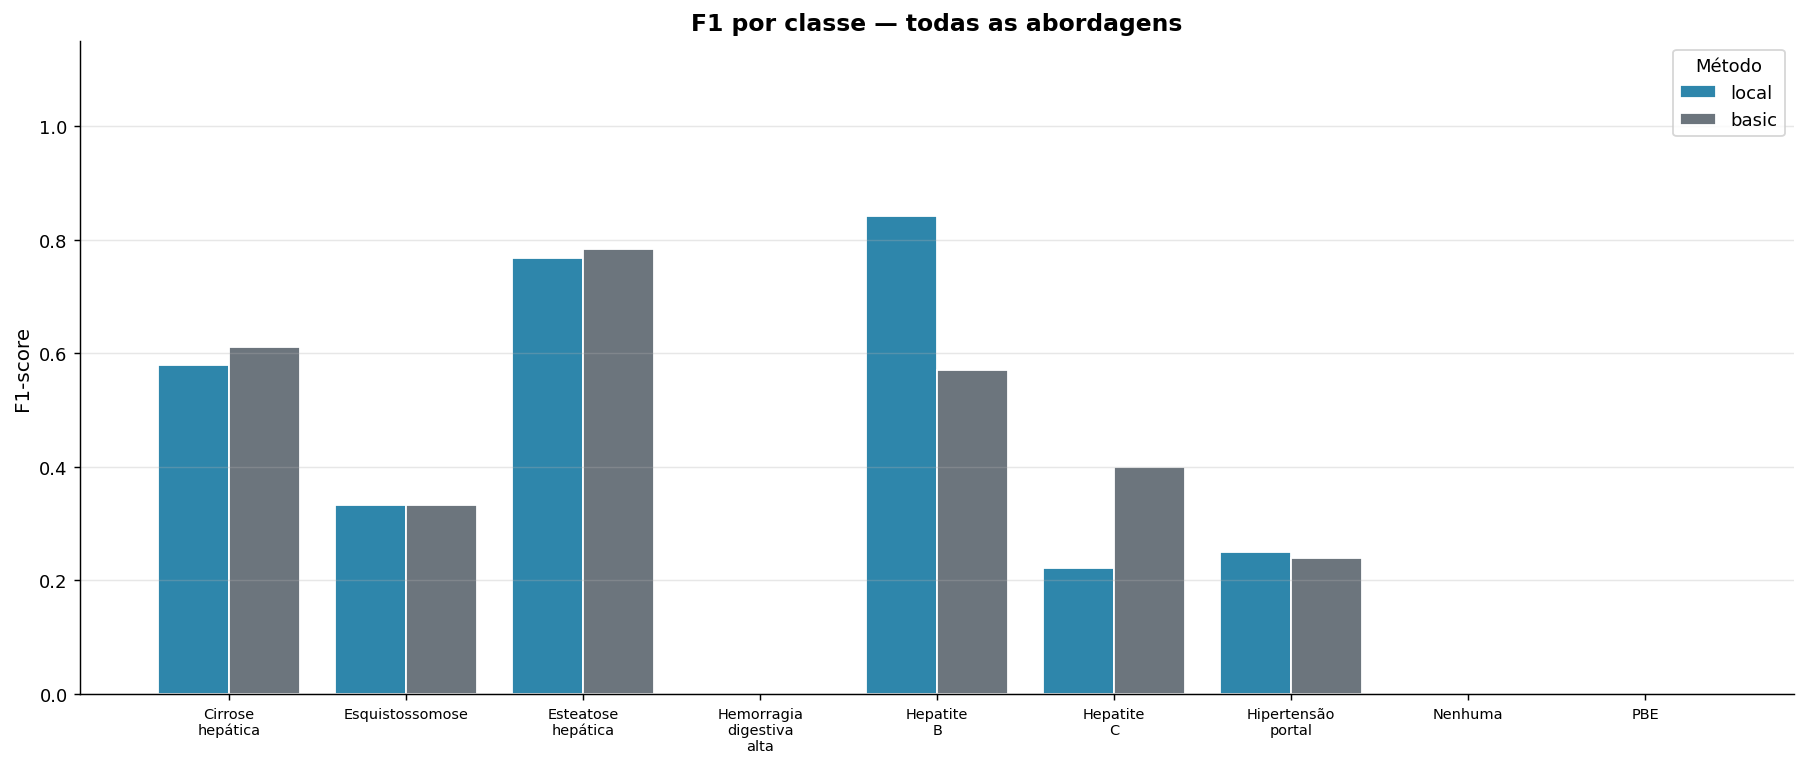

In [16]:
todas_classes = sorted(set().union(*[set(resultados[m]["classes_presentes"]) for m in ordem]))
labels_x = [LABELS_PT.get(c, c) for c in todas_classes]

fig, ax = plt.subplots(figsize=(14, 6))
n_metodos = len(ordem)
largura = 0.8 / n_metodos
x = np.arange(len(todas_classes))

for i, m in enumerate(ordem):
    f1_por_classe = (
        resultados[m]["df_metricas"].set_index("classe")["F1"].reindex(todas_classes).fillna(0.0)
    )
    ax.bar(x + i*largura - 0.4 + largura/2, f1_por_classe.values, width=largura,
           label=m, color=CORES_METODO.get(m, COR_NEUTRO), edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels([l.replace(' ', '\n') for l in labels_x], fontsize=8)
ax.set_ylim(0, 1.15)
ax.set_ylabel('F1-score')
ax.set_title('F1 por classe — todas as abordagens', fontsize=13, fontweight='bold')
ax.legend(title='Método')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_f1_por_classe_metodos.png', bbox_inches='tight')
plt.show()


## 10. Matrizes de confusão por abordagem

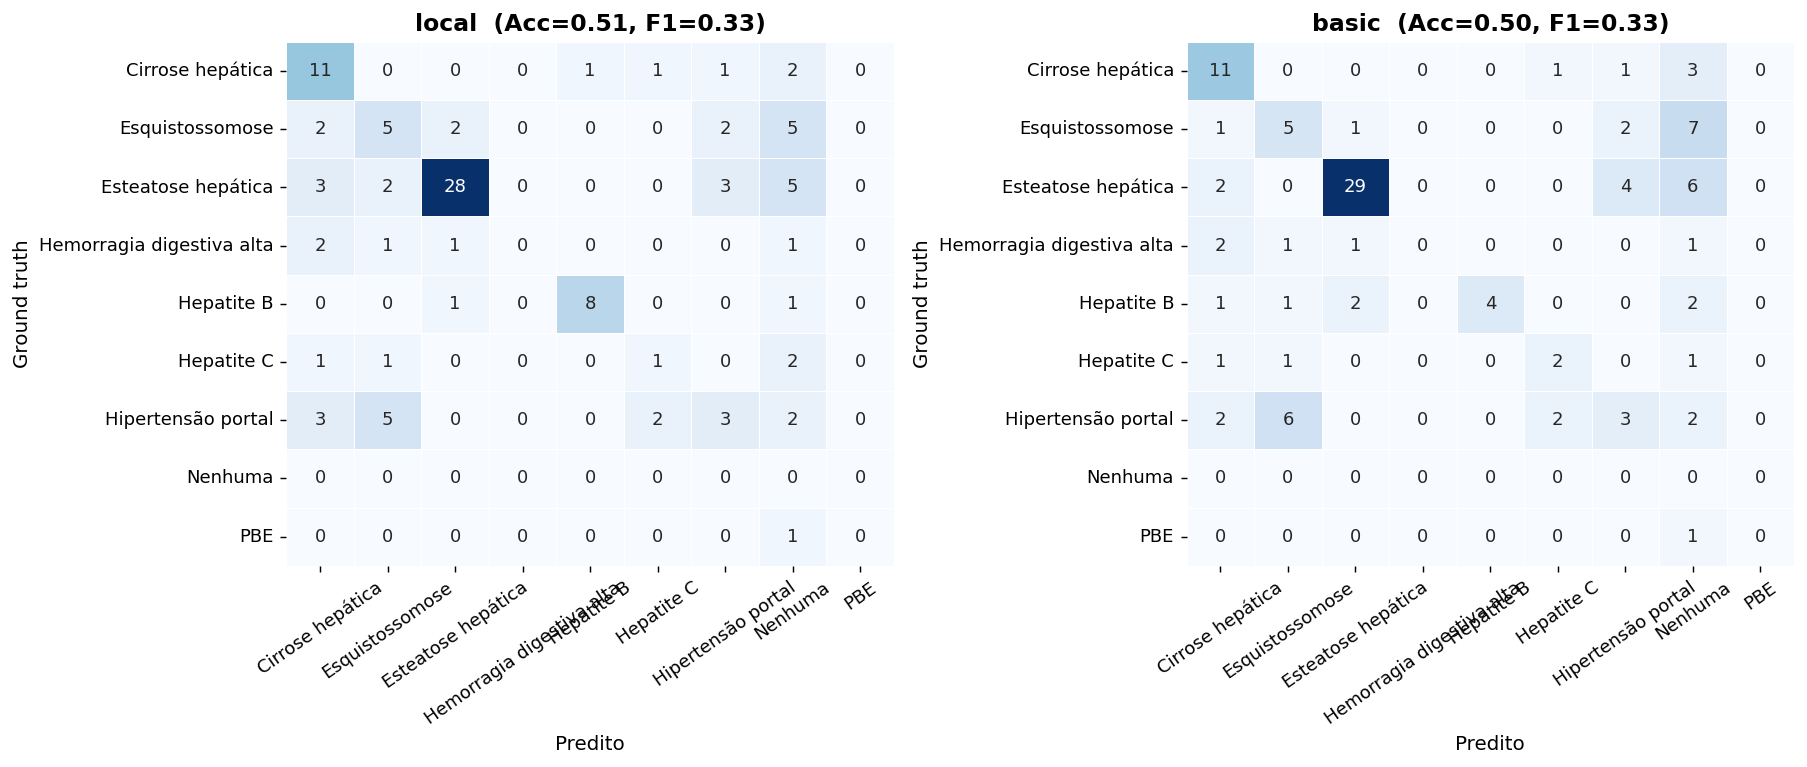

In [17]:
n = len(ordem)
n_cols = 2
n_rows = int(np.ceil(n / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7*n_cols, 6*n_rows))
axes = np.array(axes).reshape(-1)

for ax, m in zip(axes, ordem):
    r = resultados[m]
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=r["classes_presentes"])
    labels_plot = [LABELS_PT.get(c, c) for c in r["classes_presentes"]]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_plot,
                yticklabels=labels_plot, linewidths=0.5, linecolor='white', ax=ax,
                cbar=False)
    ax.set_title(f'{m}  (Acc={r["accuracy"]:.2f}, F1={r["f1_macro"]:.2f})', fontweight='bold')
    ax.set_xlabel('Predito')
    ax.set_ylabel('Ground truth')
    ax.tick_params(axis='x', rotation=35)
    ax.tick_params(axis='y', rotation=0)

for ax in axes[len(ordem):]:
    ax.axis('off')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_matrizes_confusao_metodos.png', bbox_inches='tight')
plt.show()


## 11. Testes estatísticos — melhor método vs. demais

In [18]:
from statsmodels.stats.contingency_tables import mcnemar

melhor_metodo = ordem[0]
y_true_ref = np.array(resultados[melhor_metodo]["y_true"])
acerto_melhor = (y_true_ref == np.array(resultados[melhor_metodo]["y_pred"])).astype(int)

print(f"Método de referência (melhor F1 macro): {melhor_metodo}\n")

linhas = []
for m in ordem[1:]:
    acerto_m = (y_true_ref == np.array(resultados[m]["y_pred"])).astype(int)
    b = int(((acerto_melhor == 1) & (acerto_m == 0)).sum())
    c = int(((acerto_melhor == 0) & (acerto_m == 1)).sum())
    try:
        p_valor = mcnemar([[0, b], [c, 0]], exact=(b + c < 25)).pvalue
    except ValueError:
        p_valor = np.nan
    linhas.append({
        "Comparação": f"{melhor_metodo} vs {m}",
        "Δ F1 macro": resultados[melhor_metodo]["f1_macro"] - resultados[m]["f1_macro"],
        "McNemar p-valor": p_valor,
        "Significativo (p<0.05)": bool(p_valor < 0.05) if pd.notna(p_valor) else None,
    })

df_testes = pd.DataFrame(linhas)
df_testes.to_csv(RESULTS_DIR / "testes_estatisticos_mcnemar.csv", index=False, encoding="utf-8-sig")
df_testes


Método de referência (melhor F1 macro): local



,Comparação,Δ F1 macro,McNemar p-valor,Significativo (p<0.05)
0,local vs basic,0.006008,0.831812,False


## 12. Resumo executivo

In [19]:
print('=' * 60)
print('RESUMO EXECUTIVO — comparação de abordagens de RAG')
print('=' * 60)
print(f'Prontuários avaliados : {len(gt_eval)}  (+{len(gt_fp)} falsos-positivos-puros)')
print(f'Métodos comparados    : {ordem}')
print()
for _, row in df_resumo.iterrows():
    print(
        f"  {row['Método']:<8} Accuracy={row['Accuracy']:.3f}  "
        f"F1 macro={row['F1 macro']:.3f} {row['IC95% F1 macro']}  "
        f"Kappa={row['Cohen Kappa']:.3f}  "
        f"Taxa erro CLI={row['Taxa erro CLI']:.1%}  "
        f"Sem texto-fonte={row['Taxa sem texto-fonte']:.1%}  "
        f"Taxa FP={row['Taxa falso positivo']:.1%}"
    )
print()
print(f"Melhor abordagem (F1 macro): {ordem[0]}")
print()
print('Arquivos gerados em', RESULTS_DIR)
print('  predictions_<metodo>.csv           — previsão bruta por prontuário/método')
print('  resumo_comparativo_metodos.csv     — tabela comparativa de métricas')
print('  testes_estatisticos_mcnemar.csv    — significância estatística')
print('  fig_ground_truth_distribuicao.png')
print('  fig_comparacao_metodos.png')
print('  fig_f1_por_classe_metodos.png')
print('  fig_matrizes_confusao_metodos.png')


RESUMO EXECUTIVO — comparação de abordagens de RAG
Prontuários avaliados : 109  (+32 falsos-positivos-puros)
Métodos comparados    : ['local', 'basic']

  local    Accuracy=0.514  F1 macro=0.333 [0.269, 0.429]  Kappa=0.407  Taxa erro CLI=0.0%  Sem texto-fonte=1.4%  Taxa FP=43.8%
  basic    Accuracy=0.495  F1 macro=0.327 [0.247, 0.427]  Kappa=0.386  Taxa erro CLI=0.0%  Sem texto-fonte=1.4%  Taxa FP=56.2%

Melhor abordagem (F1 macro): local

Arquivos gerados em /mnt/c/Users/Matheus/Documents/trabalho de conclusão de curso/anamnese/results/rag_comparison
  predictions_<metodo>.csv           — previsão bruta por prontuário/método
  resumo_comparativo_metodos.csv     — tabela comparativa de métricas
  testes_estatisticos_mcnemar.csv    — significância estatística
  fig_ground_truth_distribuicao.png
  fig_comparacao_metodos.png
  fig_f1_por_classe_metodos.png
  fig_matrizes_confusao_metodos.png
